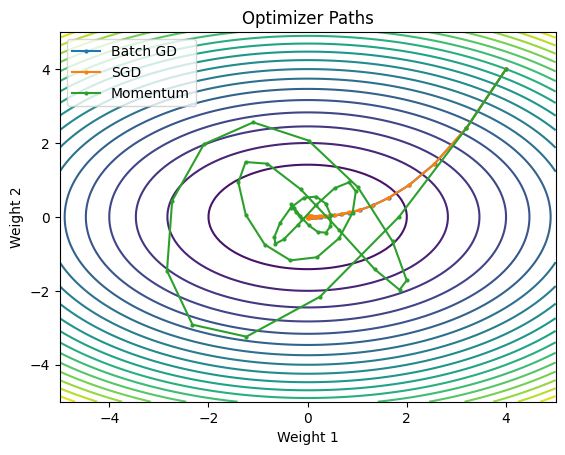

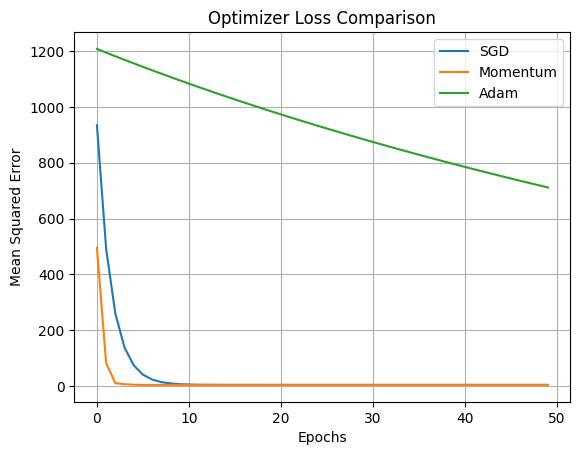

Learning Rate: 0.001 Final Loss: 191.0452880859375
Learning Rate: 0.01 Final Loss: 3.6741623878479004
Learning Rate: 0.1 Final Loss: 3.745461940765381
Learning Rate: 1.0 Final Loss: 195.03961181640625


In [6]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)

# 1. Simple Loss Function
def loss(w):
    return w[0]**2 + 2*w[1]**2

def grad(w):
    return np.array([2*w[0], 4*w[1]])

# 2. Batch GD, SGD and Momentum
def optimize(method, lr=0.1, steps=50):
    w = np.array([4.0, 4.0])
    v = np.zeros(2)
    path = [w.copy()]

    for i in range(steps):
        if method == "SGD":
            g = grad(w) + np.random.randn(2)*0.1
        else:
            g = grad(w)

        if method == "Momentum":
            v = 0.9*v + g
            w -= lr*v
        else:
            w -= lr*g

        path.append(w.copy())

    return np.array(path)

methods = ["Batch GD", "SGD", "Momentum"]
paths = {}

for m in methods:
    paths[m] = optimize(m)

# 3. Loss Contour Plot
x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x, y)
Z = X**2 + 2*Y**2

plt.contour(X, Y, Z, levels=20)
for m, path in paths.items():
    plt.plot(path[:,0], path[:,1], marker='o',
             markersize=2, label=m)

plt.xlabel("Weight 1")
plt.ylabel("Weight 2")
plt.title("Optimizer Paths")
plt.legend()
plt.show()

# 4. Delivery Dataset
N = 500
X_data = np.random.rand(N, 4)
y_data = (10 + 20*X_data[:,0] +
          15*X_data[:,1] +
          5*X_data[:,2] +
          8*X_data[:,3] +
          np.random.randn(N)*2)

# Standardization
X_data = (X_data-X_data.mean(axis=0))/X_data.std(axis=0)

# 5. Train Keras Models
optimizers = {
    "SGD": keras.optimizers.SGD(learning_rate=0.01),
    "Momentum": keras.optimizers.SGD(
        learning_rate=0.01, momentum=0.9),
    "Adam": keras.optimizers.Adam(learning_rate=0.01)
}

histories = {}

for name, opt in optimizers.items():
    model = keras.Sequential([
        keras.layers.Input(shape=(4,)),
        keras.layers.Dense(1)
    ])

    model.compile(optimizer=opt, loss='mse')

    history = model.fit(
        X_data, y_data,
        epochs=50,
        batch_size=32,
        verbose=0
    )

    histories[name] = history.history['loss']

# 6. Loss Comparison
for name, values in histories.items():
    plt.plot(values, label=name)

plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.title("Optimizer Loss Comparison")
plt.legend()
plt.grid()
plt.show()

# 7. Learning Rate Comparison
for lr in [0.001, 0.01, 0.1, 1.0]:
    model = keras.Sequential([
        keras.layers.Input(shape=(4,)),
        keras.layers.Dense(1)
    ])

    model.compile(
        optimizer=keras.optimizers.SGD(learning_rate=lr),
        loss='mse'
    )

    h = model.fit(
        X_data, y_data,
        epochs=30,
        batch_size=32,
        verbose=0
    )

    print("Learning Rate:", lr,
          "Final Loss:", h.history['loss'][-1])
